In [46]:
import pandas as pd
import numpy as np
import time
import warnings
import scipy.optimize as sco
import yfinance as yf
from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
warnings.filterwarnings('ignore')

# Define start and end as pure date objects (avoiding string parsing errors)
start = (datetime.now() - relativedelta(months=36)).date()
end = (datetime.now() + timedelta(days=1)).date()

# Tickers list
tickers = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", 
    "ICICIBANK.NS", "HINDUNILVR.NS", "ITC.NS", "LT.NS", 
    "BHARTIARTL.NS"
]

print("Downloading data for all tickers in a single batch...")
data = yf.download(tickers, start=start, end=end)

# Extract 'Adj Close' or 'Close' safely
if isinstance(data.columns, pd.MultiIndex):
    if 'Adj Close' in data.columns.levels[0]:
        final_data = data['Adj Close']
    elif 'Close' in data.columns.levels[0]:
        final_data = data['Close']
    else:
        final_data = data.xs('Close', axis=1, level=0)
else:
    final_data = data

# Sort by date, forward/backward fill missing values, and set index
final_data = final_data.sort_index().ffill().bfill()
final_data.columns.name = "ticker"

print("✅ Data successfully downloaded and preprocessed!")
display(final_data.head())
display(final_data.tail())

# --- Financial Calculations ---
returns = final_data.pct_change().dropna()
mean_returns = returns.mean()
cov_matrix = returns.cov()
risk_free_rate = 0.0278  # 2.78% risk-free rate proxy
num_assets = len(mean_returns)

# --- Portfolio Performance Function ---
def portfolios_annualized_performance(weights, mean_returns, cov_matrix):
    p_returns = np.sum(mean_returns * weights) * 252
    p_std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights))) * np.sqrt(252)
    return p_std, p_returns

# --- Objective Functions ---
def neg_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate, lambda_reg=0.01):
    p_var, p_ret = portfolios_annualized_performance(weights, mean_returns, cov_matrix)
    reg_term = lambda_reg * np.sum(weights ** 2)  # Regularization term
    return -(p_ret - risk_free_rate) / p_var + reg_term

def portfolio_volatility(weights, mean_returns, cov_matrix):
    return portfolios_annualized_performance(weights, mean_returns, cov_matrix)[0]

def max_sharpe_ratio(mean_returns, cov_matrix, risk_free_rate):
    constraints = ({'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1},)
    bounds = tuple((0.0, 0.25) for _ in range(num_assets))
    init_guess = num_assets * [1.0 / num_assets]
    
    result = sco.minimize(
        neg_sharpe_ratio,
        init_guess,
        args=(mean_returns, cov_matrix, risk_free_rate),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    return result

def min_variance(mean_returns, cov_matrix):
    constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1},)
    bounds = tuple((0.0, 0.25) for _ in range(num_assets))
    init_guess = num_assets * [1.0 / num_assets]
    
    result = sco.minimize(
        portfolio_volatility,
        init_guess,
        args=(mean_returns, cov_matrix),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    return result

def efficient_return(mean_returns, cov_matrix, target):
    def portfolio_returns(weights):
        return portfolios_annualized_performance(weights, mean_returns, cov_matrix)[1]

    constraints = (
        {'type': 'eq', 'fun': lambda x: portfolio_returns(x) - target},
        {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
    )
    bounds = tuple((0.0, 0.25) for _ in range(num_assets))
    init_guess = num_assets * [1.0 / num_assets]
    
    result = sco.minimize(
        portfolio_volatility,
        init_guess,
        args=(mean_returns, cov_matrix),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    return result

def efficient_frontier(mean_returns, cov_matrix, returns_range):
    efficients = []
    for ret in returns_range:
        efficients.append(efficient_return(mean_returns, cov_matrix, ret))
    return efficients  # Fixed: unindented outside the loop

# --- Executing Optimizations ---
max_sharpe = max_sharpe_ratio(mean_returns, cov_matrix, risk_free_rate)
sdp, rp = portfolios_annualized_performance(max_sharpe.x, mean_returns, cov_matrix)

max_sharpe_allocation = pd.DataFrame(max_sharpe.x, index=final_data.columns, columns=['allocation'])
max_sharpe_allocation['allocation'] = (max_sharpe_allocation['allocation'] * 100).round(2)
max_sharpe_allocation = max_sharpe_allocation.T

min_vol = min_variance(mean_returns, cov_matrix)
sdp_min, rp_min = portfolios_annualized_performance(min_vol.x, mean_returns, cov_matrix)

min_vol_allocation = pd.DataFrame(min_vol.x, index=final_data.columns, columns=['allocation'])
min_vol_allocation['allocation'] = (min_vol_allocation['allocation'] * 100).round(2)
min_vol_allocation = min_vol_allocation.T

an_vol = returns.std() * np.sqrt(252)
an_rt = mean_returns * 252

sharpe_ratio_max_return = round((rp - risk_free_rate) / sdp, 4)
sharpe_ratio_min_volatility = round((rp_min - risk_free_rate) / sdp_min, 4)

# --- Print Results ---
print("-" * 80)
print("Maximum Sharpe Ratio Portfolio Allocation\n")
print("Annualised Return:", round(rp, 3))
print("Annualised Volatility:", round(sdp, 3))
print("Sharpe Ratio Max Return:", sharpe_ratio_max_return)
print("\n")
display(max_sharpe_allocation.T.sort_values(by='allocation', ascending=False))

print("-" * 80)
print("Minimum Volatility Portfolio Allocation\n")
print("Annualised Return:", round(rp_min, 3))
print("Annualised Volatility:", round(sdp_min, 3))  # Fixed variable bug here
print("Sharpe Ratio Min Volatility:", sharpe_ratio_min_volatility)
print("\n")
display(min_vol_allocation.T.sort_values(by='allocation', ascending=False))

print("-" * 80)
print("Individual Stock Returns and Volatility\n")
df_stats = []
for ticker in final_data.columns:
    df_stats.append({
        'ticker': ticker,
        'annualised_return': round(an_rt[ticker], 2),
        'annualised_volatility': round(an_vol[ticker], 2)
    })

df_stats = pd.DataFrame(df_stats).sort_values(by='annualised_return', ascending=False)
display(df_stats.reset_index(drop=True))
print("-" * 80)

[*********************100%***********************]  9 of 9 completed

✅ Data successfully downloaded and preprocessed!


ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,,
2023-10-23,914.836853,721.047424,2345.938965,907.303711,1281.544067,374.156464,2879.974854,1118.116455,3099.896484
2023-10-25,898.571716,716.475098,2340.082520,893.790955,1262.560303,371.409729,2838.892090,1115.522583,3081.670898
2023-10-26,881.917175,700.627930,2339.232178,886.522461,1252.791992,372.826050,2788.755859,1099.984985,3033.174072
2023-10-27,890.780151,703.380798,2344.569580,890.522583,1272.052124,372.311005,2825.068115,1119.400879,3046.082520
2023-10-30,902.126709,711.017151,2341.593750,902.376709,1269.011108,369.478455,2848.871094,1142.472534,3071.171875


ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,,
2026-10-14,1794.599976,710.700012,1895.500000,1338.599976,1088.000000,261.500000,3642.000000,1174.599976,2304.899902
2026-10-15,1854.000000,726.849976,1897.099976,1389.400024,1110.000000,263.899994,3632.000000,1215.000000,2350.000000
2026-10-16,1905.000000,728.849976,1893.800049,1397.000000,1161.199951,263.500000,3627.100098,1211.199951,2465.000000
2026-10-19,1875.199951,712.000000,1853.199951,1381.000000,1130.699951,260.799988,3661.899902,1202.000000,2460.899902
2026-10-21,1869.300049,700.000000,1834.400024,1385.699951,1162.750000,260.399994,3626.000000,1203.000000,2508.300049


--------------------------------------------------------------------------------
Maximum Sharpe Ratio Portfolio Allocation

Annualised Return: 0.146
Annualised Volatility: 0.156
Sharpe Ratio Max Return: 0.7561




...

--------------------------------------------------------------------------------
Minimum Volatility Portfolio Allocation

Annualised Return: 0.034
Annualised Volatility: 0.124
Sharpe Ratio Min Volatility: 0.0496




,allocation
ticker,
HINDUNILVR.NS,18.95
ICICIBANK.NS,18.24
ITC.NS,17.15
BHARTIARTL.NS,12.57
HDFCBANK.NS,11.53
TCS.NS,10.83
RELIANCE.NS,7.97
INFY.NS,2.76
LT.NS,0.00


--------------------------------------------------------------------------------
Individual Stock Returns and Volatility



,ticker,annualised_return,annualised_volatility
0,BHARTIARTL.NS,0.27,0.22
1,ICICIBANK.NS,0.16,0.19
2,LT.NS,0.11,0.26
3,RELIANCE.NS,0.05,0.21
4,HDFCBANK.NS,0.01,0.21
5,INFY.NS,0.00,0.27
6,TCS.NS,-0.04,0.24
7,HINDUNILVR.NS,-0.06,0.20
8,ITC.NS,-0.11,0.19


--------------------------------------------------------------------------------


Generating Efficient Frontier Plot...


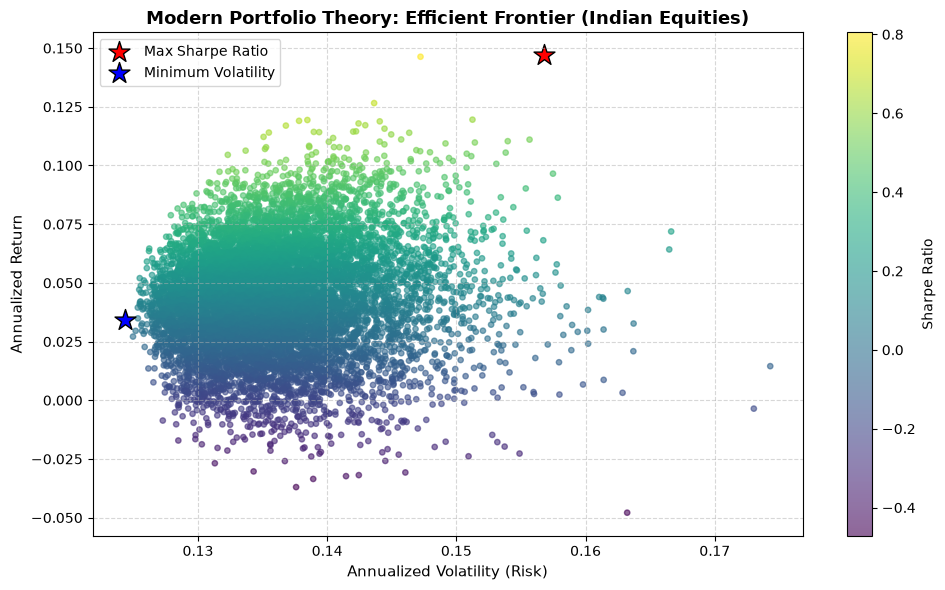

Generating Historical Backtest Plot...


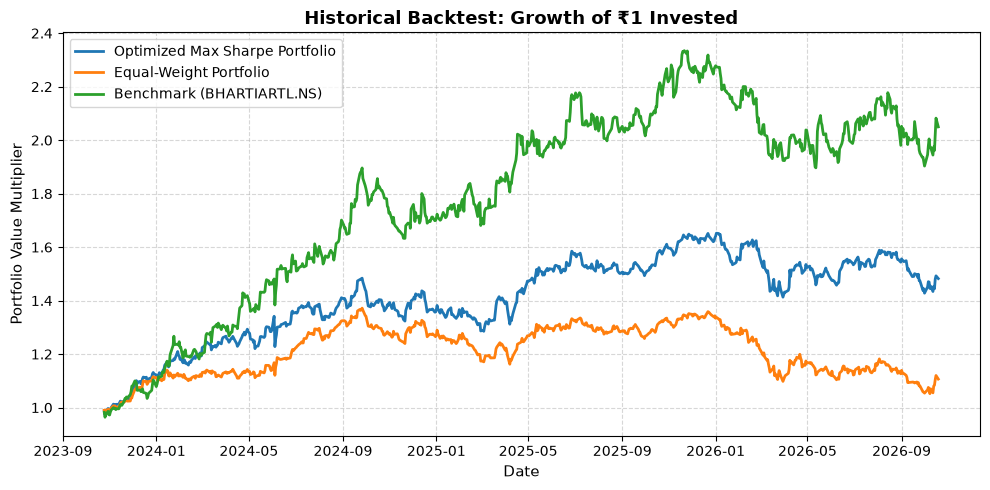

In [45]:
# ==========================================
# VISUALIZATION 1: EFFICIENT FRONTIER PLOT
# ==========================================
import matplotlib.pyplot as plt
print("Generating Efficient Frontier Plot...")
np.random.seed(42)
num_portfolios = 10000
all_weights = np.zeros((num_portfolios, len(final_data.columns)))
ret_arr = np.zeros(num_portfolios)
vol_arr = np.zeros(num_portfolios)
sharpe_arr = np.zeros(num_portfolios)

for idx in range(num_portfolios):
    weights = np.random.random(len(final_data.columns))
    weights = weights / np.sum(weights)
    all_weights[idx, :] = weights
    vol, ret = portfolios_annualized_performance(weights, mean_returns, cov_matrix)
    vol_arr[idx] = vol
    ret_arr[idx] = ret
    sharpe_arr[idx] = (ret - risk_free_rate) / vol

plt.figure(figsize=(10, 6))
plt.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='viridis', marker='o', s=15, alpha=0.6)
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Annualized Volatility (Risk)', fontsize=11)
plt.ylabel('Annualized Return', fontsize=11)
plt.title('Modern Portfolio Theory: Efficient Frontier (Indian Equities)', fontsize=13, fontweight='bold')

# Plot optimal portfolios
plt.scatter(sdp, rp, marker='*', color='red', s=250, label='Max Sharpe Ratio', edgecolors='black')
plt.scatter(sdp_min, rp_min, marker='*', color='blue', s=250, label='Minimum Volatility', edgecolors='black')

plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 2: HISTORICAL BACKTEST
# ==========================================
print("Generating Historical Backtest Plot...")
portfolio_daily_returns = returns.dot(max_sharpe.x)
equal_weights = np.array([1 / num_assets] * num_assets)
equal_daily_returns = returns.dot(equal_weights)

cumulative_perf = pd.DataFrame({
    "Optimized Max Sharpe Portfolio": (1 + portfolio_daily_returns).cumprod(),
    "Equal-Weight Portfolio": (1 + equal_daily_returns).cumprod(),
    f"Benchmark ({final_data.columns[0]})": (1 + returns.iloc[:, 0]).cumprod()
})

plt.figure(figsize=(10, 5))
for col in cumulative_perf.columns:
    plt.plot(cumulative_perf.index, cumulative_perf[col], label=col, linewidth=2)

plt.title('Historical Backtest: Growth of ₹1 Invested', fontsize=13, fontweight='bold')
plt.xlabel('Date', fontsize=11)
plt.ylabel('Portfolio Value Multiplier', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()